<p style="font-size:300%; background-color:#ffe6f0; color:#0044cc; text-align:center; line-height:80px; margin:0; padding:0;"> <b>Detectores - Descriptores</b> </p>

<p style="font-size:240%; background-color:#ffe6f0; color:#cc0000; text-align:center; line-height:60px; margin:0; padding:0;">
  <b>Inteligencia Artificial & Mini Robots</b>
</p>

<p style="font-size:200%; text-align:center; line-height:40px; margin:0;">
  <br><b>Prof. Flavio Prieto</b>
</p>

<p style="font-size:160%; text-align:center; line-height:25px; margin:0;">
  email: <a href="mailto:faprietoo@unal.edu.co">faprietoo@unal.edu.co</a>
</p>

<p style="font-size:180%; text-align:center; line-height:30px; margin:0;">
  <br><b>DEPARTAMENTO DE INGENIERÍA MECÁNICA Y MECATRÓNICA</b>
</p>

<p style="font-size:180%; text-align:center; line-height:30px; margin:0;">
  Facultad de Ingeniería
</p>

<p style="font-size:160%; text-align:center; line-height:30px; margin:0;">
  Universidad Nacional de Colombia – Sede Bogotá
</p>

<div style="text-align:center; margin-top:20px; margin-bottom:10px;">
  <img src="Fig/Escudo_UN.png" alt="Escudo UNAL" width="90" style="border:none;">
</div>


<hr style="border: 4px solid red;">

# DETECTORES

## Detector de Harris

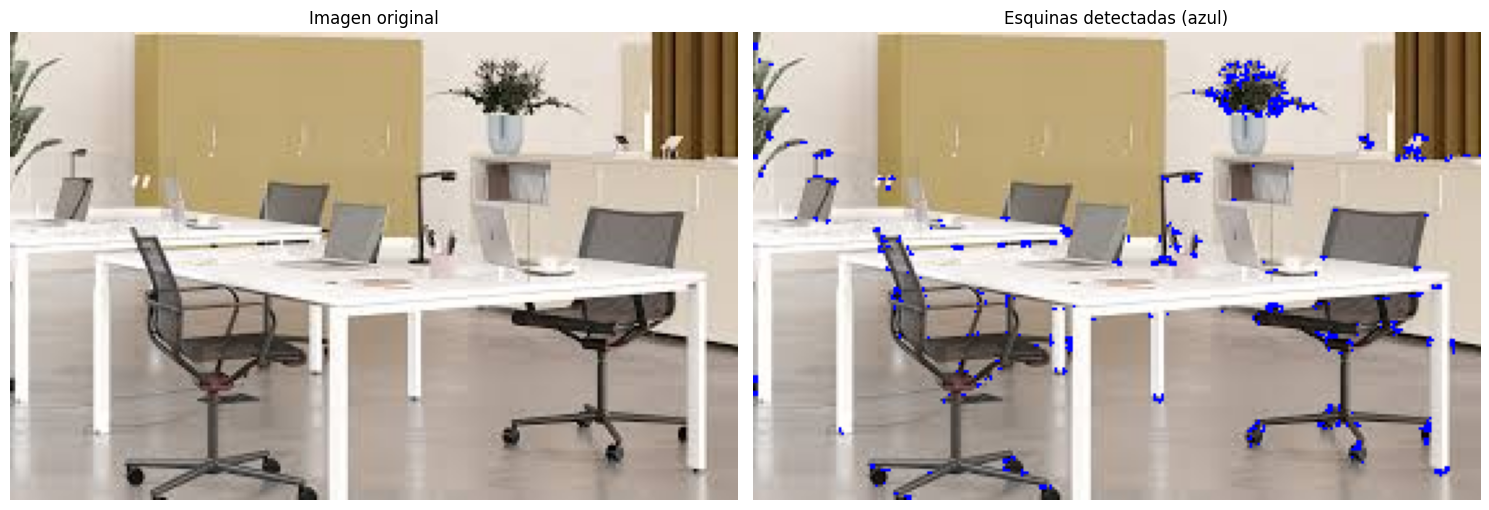

In [1]:
#=========================================================
# Detector de esquinas de Harris (versión mejorada)
#=========================================================
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Cargar la imagen
img_color = cv2.imread('fig/Notebook/Oficina.jpg')
if img_color is None:
    raise FileNotFoundError("No se encontró la imagen fig/Notebook/Oficna.jpg")

# Convertir a escala de grises
gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)
gray = np.float32(gray)

# Aplicar el detector de Harris
block_size = 2
ksize = 3
k = 0.04
R = cv2.cornerHarris(gray, block_size, ksize, k)

# Normalizar el mapa de respuesta
R_norm = cv2.normalize(R, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)
R_norm = np.uint8(R_norm)

# Detección de esquinas
threshold = 0.01 * R.max()
img_corners = img_color.copy()
img_corners[R > threshold] = [255, 0, 0]  # Esquinas en azul (BGR)

# Mostrar resultados
plt.figure(figsize=(15,5))

plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
plt.title('Imagen original')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(img_corners, cv2.COLOR_BGR2RGB))
plt.title('Esquinas detectadas (azul)')
plt.axis('off')

plt.tight_layout()
plt.show()


<hr style="border: 4px solid red;">

## DoG

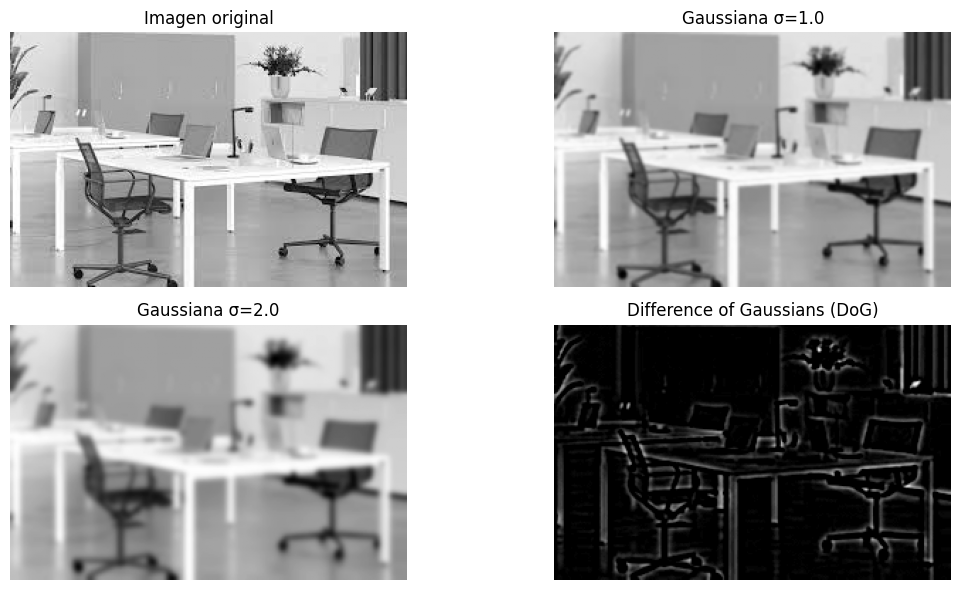

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# --- Parámetros ---
sigma1 = 1.0
sigma2 = 2.0

# --- Cargar imagen ---
img = cv2.imread('fig/Notebook/oficina.jpg', cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("No se encontró la imagen 'oficina.jpg'. Asegúrate de que esté en el mismo directorio.")

# --- Aplicar filtros Gaussianos ---
gauss1 = cv2.GaussianBlur(img, (0, 0), sigma1)
gauss2 = cv2.GaussianBlur(img, (0, 0), sigma2)

# --- Difference of Gaussians (DoG) ---
DoG = cv2.subtract(gauss1, gauss2)

# --- Normalizar para visualizar mejor ---
DoG_norm = cv2.normalize(DoG, None, 0, 255, cv2.NORM_MINMAX)

# --- Mostrar resultados ---
plt.figure(figsize=(12, 6))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Imagen original')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(gauss1, cmap='gray')
plt.title(f'Gaussiana σ={sigma1}')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(gauss2, cmap='gray')
plt.title(f'Gaussiana σ={sigma2}')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(DoG_norm, cmap='gray')
plt.title('Difference of Gaussians (DoG)')
plt.axis('off')

plt.tight_layout()
plt.show()


<hr style="border: 4px solid red;">

### FAST

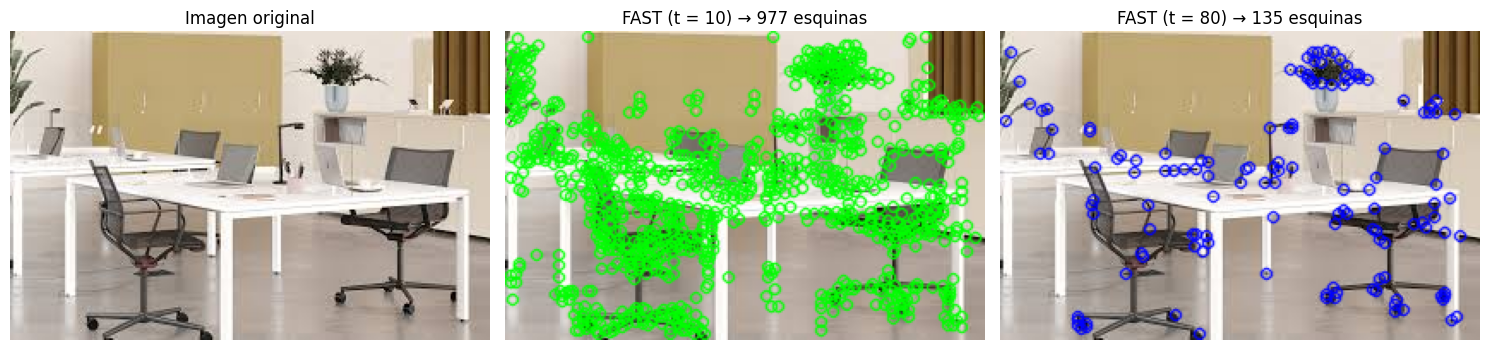

------------------------------------------------
Parámetros del detector FAST (t = 10):
Threshold: 10
Non-maximum Suppression: True
Tipo: 2
Total de esquinas detectadas: 977
------------------------------------------------
Parámetros del detector FAST (t = 80):
Threshold: 80
Non-maximum Suppression: True
Tipo: 2
Total de esquinas detectadas: 135
------------------------------------------------


In [22]:
import cv2
import matplotlib.pyplot as plt

# Ruta de la imagen
img_path = "fig/Notebook/Oficina.jpg"

# Cargar imagen
img = cv2.imread(img_path)
if img is None:
    raise FileNotFoundError(f"No se encontró la imagen en la ruta: {img_path}")

# Convertir a escala de grises
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# --- Detector FAST con t = 10 ---
fast_10 = cv2.FastFeatureDetector_create()
fast_10.setThreshold(10)
fast_10.setNonmaxSuppression(True)

keypoints_10 = fast_10.detect(gray, None)
img_fast10 = cv2.drawKeypoints(img, keypoints_10, None, color=(0, 255, 0))

# --- Detector FAST con t = 80 ---
fast_80 = cv2.FastFeatureDetector_create()
fast_80.setThreshold(80)
fast_80.setNonmaxSuppression(True)

keypoints_80 = fast_80.detect(gray, None)
img_fast80 = cv2.drawKeypoints(img, keypoints_80, None, color=(255, 0, 0))

# --- Mostrar resultados ---
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Imagen original')
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(cv2.cvtColor(img_fast10, cv2.COLOR_BGR2RGB))
plt.title(f'FAST (t = 10) → {len(keypoints_10)} esquinas')
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(cv2.cvtColor(img_fast80, cv2.COLOR_BGR2RGB))
plt.title(f'FAST (t = 80) → {len(keypoints_80)} esquinas')
plt.axis('off')

plt.tight_layout()
plt.show()

# --- Imprimir parámetros ---
print("------------------------------------------------")
print("Parámetros del detector FAST (t = 10):")
print(f"Threshold: {fast_10.getThreshold()}")
print(f"Non-maximum Suppression: {fast_10.getNonmaxSuppression()}")
print(f"Tipo: {fast_10.getType()}")
print(f"Total de esquinas detectadas: {len(keypoints_10)}")
print("------------------------------------------------")

print("Parámetros del detector FAST (t = 80):")
print(f"Threshold: {fast_80.getThreshold()}")
print(f"Non-maximum Suppression: {fast_80.getNonmaxSuppression()}")
print(f"Tipo: {fast_80.getType()}")
print(f"Total de esquinas detectadas: {len(keypoints_80)}")
print("------------------------------------------------")


<hr style="border: 4px solid red;">

# DESCRIPTORES

## SIFT

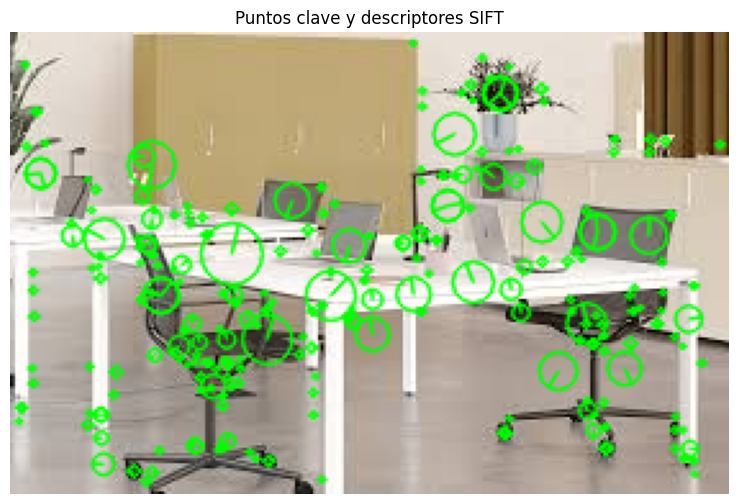

In [23]:
import cv2
import matplotlib.pyplot as plt

# Ruta de la imagen
img_path = "fig/Notebook/Oficina.jpg"

# Cargar imagen
img = cv2.imread(img_path)
if img is None:
    raise FileNotFoundError(f"No se encontró la imagen en la ruta: {img_path}")

# Convertir a escala de grises
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Crear objeto SIFT
sift = cv2.SIFT_create()

# Detectar puntos clave y calcular descriptores
keypoints, descriptors = sift.detectAndCompute(gray, None)

# Dibujar los puntos clave sobre la imagen
img_sift = cv2.drawKeypoints(
    img, keypoints, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS,
    color=(0, 255, 0)
)

# Mostrar resultados
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(img_sift, cv2.COLOR_BGR2RGB))
plt.title("Puntos clave y descriptores SIFT")
plt.axis("off")
plt.show()



Total de descriptores detectados: 279
Tamaño de cada descriptor: 128 elementos

Mostrando histograma del descriptor #0


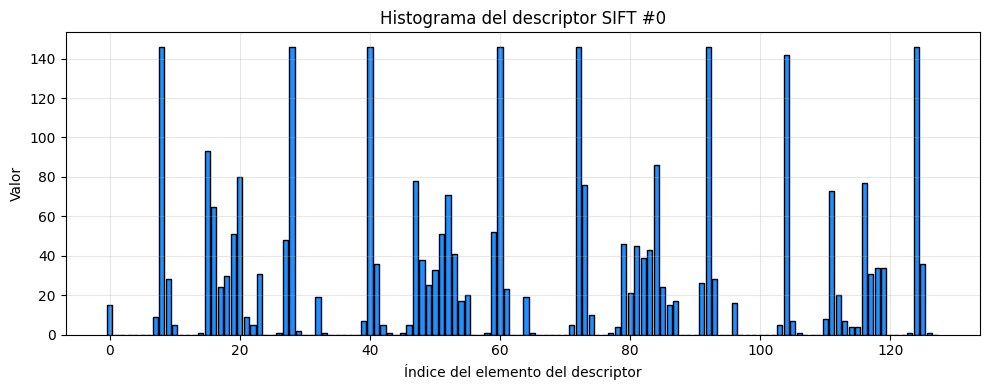

In [26]:
# Mostrar información
print(f"Total de descriptores detectados: {len(keypoints)}")
if descriptors is not None:
    print(f"Tamaño de cada descriptor: {descriptors.shape[1]} elementos")
else:
    print("No se calcularon descriptores.")


# ==========================================
# Mostrar un descriptor específico como histograma
# ==========================================
if descriptors is not None and len(descriptors) > 0:
    idx = 0  # índice del descriptor que quieres visualizar
    desc = descriptors[idx]

    print(f"\nMostrando histograma del descriptor #{idx}")

    plt.figure(figsize=(10, 4))
    plt.bar(np.arange(len(desc)), desc, color='dodgerblue', edgecolor='black')
    plt.title(f"Histograma del descriptor SIFT #{idx}")
    plt.xlabel("Índice del elemento del descriptor")
    plt.ylabel("Valor")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("No se calcularon descriptores.")

<hr style="border: 4px solid red;">

## SURF

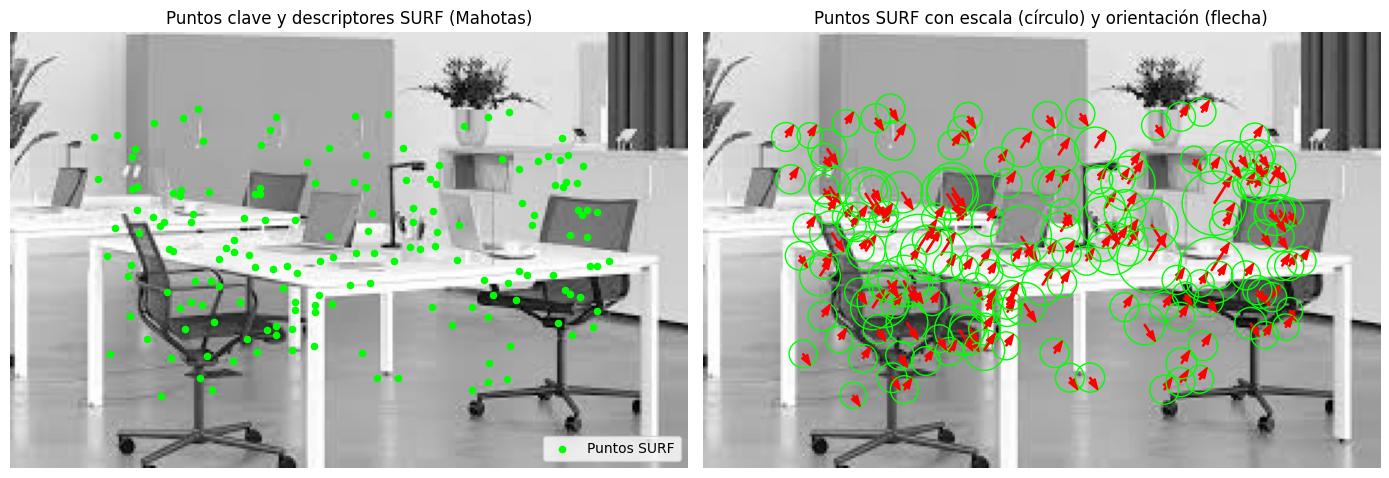

In [27]:
import numpy as np
import mahotas
from mahotas.features import surf
import matplotlib.pyplot as plt


# Ruta de la imagen
img_path = "fig/Notebook/Oficina.jpg"

# Cargar imagen
# Cargar imagen
img = cv2.imread(img_path)
if img is None:
    raise FileNotFoundError(f"No se encontró la imagen en la ruta: {img_path}")

# Convertir a escala de grises
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Detectar puntos SURF y calcular descriptores
spoints = surf.surf(gray)


# Extraer información
ys, xs = spoints[:, 0], spoints[:, 1]
scales = spoints[:, 2]
orientations = spoints[:, 4]

# Crear figura con dos subplots en una fila
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ==========================
# Imagen 1: puntos detectados
# ==========================
axes[0].imshow(gray, cmap='gray')
axes[0].scatter(xs, ys, s=20, c='lime', marker='o', label='Puntos SURF')
axes[0].set_title("Puntos clave y descriptores SURF (Mahotas)")
axes[0].axis('off')
axes[0].legend(loc='lower right')

# ==========================
# Imagen 2: escala y orientación
# ==========================
axes[1].imshow(gray, cmap='gray')

for (x, y, s, theta) in zip(xs, ys, scales, orientations):
    radius = 3 * s  # radio proporcional a la escala
    dx = radius * np.cos(theta)
    dy = radius * np.sin(theta)

    circ = plt.Circle((x, y), radius, color='lime', fill=False, linewidth=1)
    axes[1].add_patch(circ)
    axes[1].arrow(
        x, y, dx, dy,
        color='red', width=0.5, head_width=3, length_includes_head=True
    )

axes[1].set_title("Puntos SURF con escala (círculo) y orientación (flecha)")
axes[1].axis('off')

# Ajustar espaciado
plt.tight_layout()
plt.show()




Total de puntos detectados: 165
Tamaño de cada descriptor: 64 elementos
Tamaño de cada descriptor: 65 elementos

Mostrando descriptor #0 en posición (x=199.1, y=108.0)


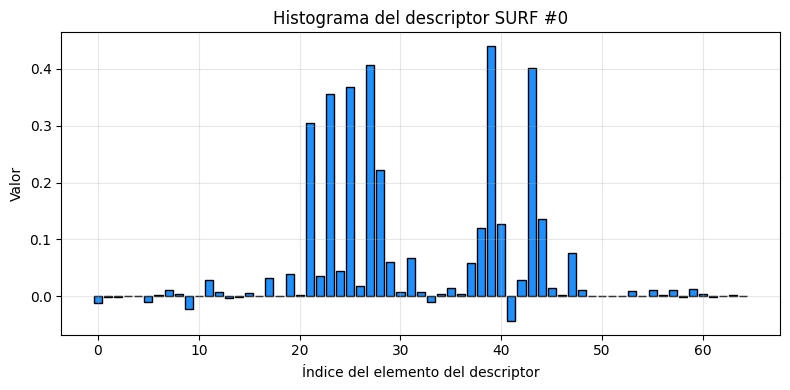

In [28]:
# Mostrar información sobre los descriptores

print(f"\n\nTotal de puntos detectados: {len(spoints)}")

if spoints.shape[0] > 0:
    descriptor_length = spoints.shape[1] - 5
    print(f"Tamaño de cada descriptor: {descriptor_length-1} elementos")
else:
    print("No se calcularon descriptores.")



if len(spoints) > 0:
    # Extraer los descriptores (desde la columna 5 en adelante)
    descriptors = spoints[:, 5:]
    print(f"Tamaño de cada descriptor: {descriptors.shape[1]} elementos")

    # Elegir un descriptor (por ejemplo, el primero)
    idx = 0
    desc = descriptors[idx]

    # Mostrar posición del punto correspondiente
    y, x = spoints[idx, 0], spoints[idx, 1]
    print(f"\nMostrando descriptor #{idx} en posición (x={x:.1f}, y={y:.1f})")

    # Mostrar histograma
    plt.figure(figsize=(8, 4))
    plt.bar(np.arange(len(desc)), desc, color='dodgerblue', edgecolor='black')
    plt.title(f"Histograma del descriptor SURF #{idx}")
    plt.xlabel("Índice del elemento del descriptor")
    plt.ylabel("Valor")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

else:
    print("No se calcularon descriptores.")


<hr style="border: 4px solid red;">

## ORB

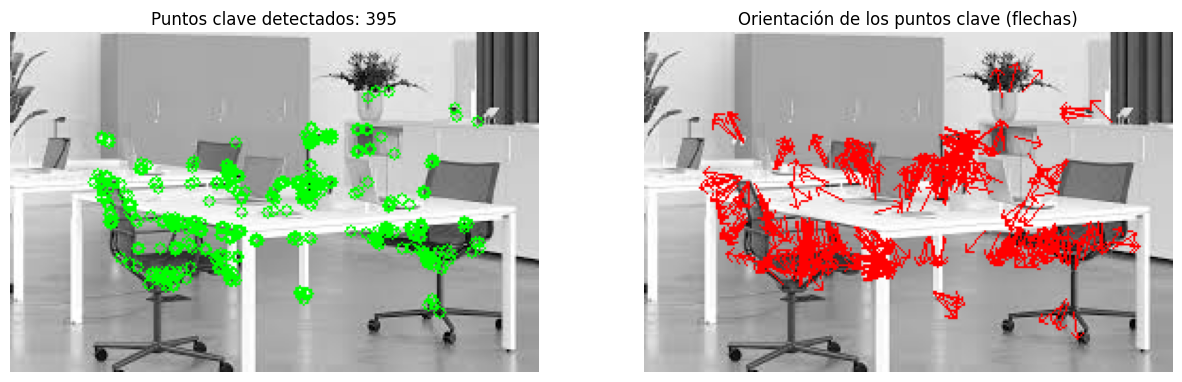

Total de puntos clave: 395
Dimensión de cada descriptor: 32 bytes (~256 bits)


In [33]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Ruta de la imagen
img_path = "fig/Notebook/Oficina.jpg"

# Cargar imagen en escala de grises
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError(f"No se encontró la imagen en la ruta: {img_path}")

# Crear detector ORB
orb = cv2.ORB_create(nfeatures=500)

# Detectar puntos clave y descriptores
keypoints, descriptors = orb.detectAndCompute(img, None)

# Imagen en color para visualización
img_kp = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
img_orient = img_kp.copy()

# Dibujar solo los puntos clave (izquierda)
for kp in keypoints:
    x, y = int(kp.pt[0]), int(kp.pt[1])
    cv2.circle(img_kp, (x, y), 3, (0, 255, 0), 1)

# Dibujar flechas de orientación (derecha)
r = 15
for kp in keypoints:
    x, y = int(kp.pt[0]), int(kp.pt[1])
    angle = np.deg2rad(kp.angle)
    x2 = int(x + r * np.cos(angle))
    y2 = int(y - r * np.sin(angle))
    cv2.arrowedLine(img_orient, (x, y), (x2, y2), (0, 0, 255), 1, tipLength=0.3)

# Mostrar lado a lado
fig, axs = plt.subplots(1, 2, figsize=(15, 8))
axs[0].imshow(cv2.cvtColor(img_kp, cv2.COLOR_BGR2RGB))
axs[0].set_title(f"Puntos clave detectados: {len(keypoints)}")
axs[0].axis("off")

axs[1].imshow(cv2.cvtColor(img_orient, cv2.COLOR_BGR2RGB))
axs[1].set_title("Orientación de los puntos clave (flechas)")
axs[1].axis("off")

plt.show()

print(f"Total de puntos clave: {len(keypoints)}")
print(f"Dimensión de cada descriptor: {descriptors.shape[1]} bytes (~{descriptors.shape[1]*8} bits)")


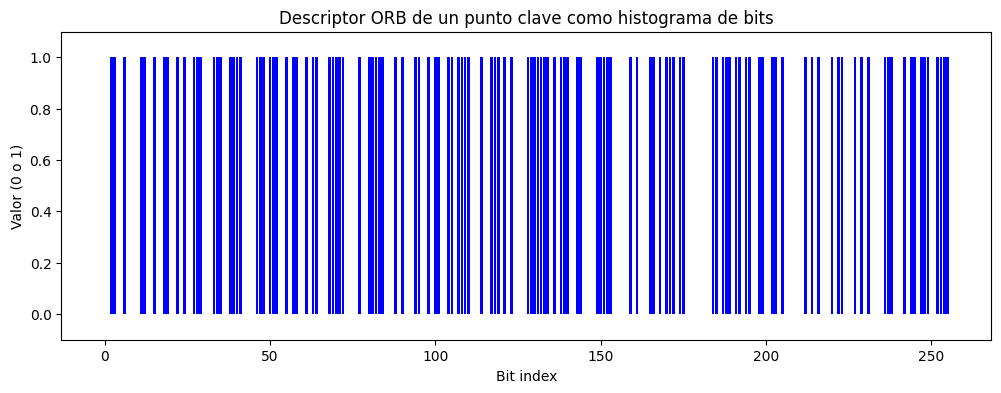

In [35]:
# Elegir un descriptor de ejemplo (el primero)
desc = descriptors[0]

# Convertir cada byte a bits (256 bits)
bits = np.unpackbits(desc)

# Mostrar como histograma
plt.figure(figsize=(12,4))
plt.bar(range(len(bits)), bits, color='blue')
plt.title("Descriptor ORB de un punto clave como histograma de bits")
plt.xlabel("Bit index")
plt.ylabel("Valor (0 o 1)")
plt.ylim(-0.1, 1.1)
plt.show()

<hr style="border: 4px solid red;">

# MATCHING

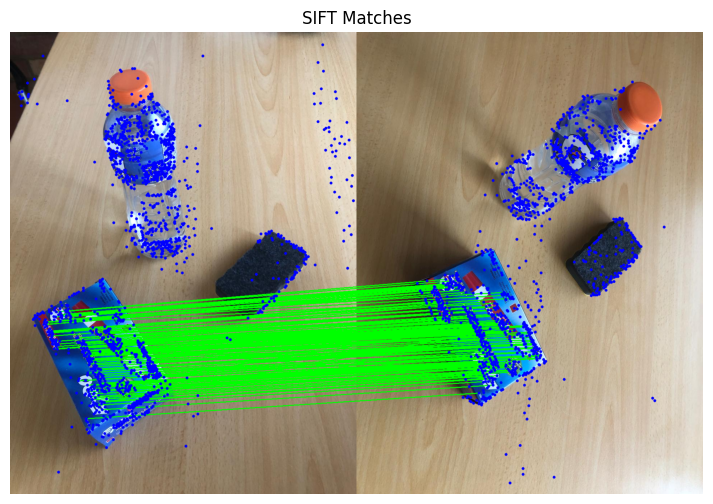

In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import mahotas

# -------------------------------
# Cargar imágenes
# -------------------------------
#img1_path = "fig/Notebook/Oficina1.jpeg"
#img2_path = "fig/Notebook/Oficina2.jpeg"

img1_path = "fig/Notebook/Objetos1.jpeg"
img2_path = "fig/Notebook/Objetos3.jpeg"

img1 = cv2.imread(img1_path)
img2 = cv2.imread(img2_path)

if img1 is None or img2 is None:
    raise FileNotFoundError("Una de las imágenes no se encontró en la ruta especificada.")

# Convertir a escala de grises
gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

# -------------------------------
# Función para mostrar matches
# -------------------------------
def draw_matches(img1, kp1, img2, kp2, matches, title):
    # Crear imagen concatenada
    h1, w1 = img1.shape[:2]
    h2, w2 = img2.shape[:2]
    out_img = np.zeros((max(h1, h2), w1 + w2, 3), dtype=np.uint8)
    out_img[:h1, :w1] = img1
    out_img[:h2, w1:w1+w2] = img2

    # Dibujar líneas entre puntos coincidentes
    for m in matches:
        pt1 = tuple(np.round(kp1[m[0]]).astype(int))
        pt2 = tuple(np.round(kp2[m[1]]).astype(int) + np.array([w1, 0]))
        color = (0, 255, 0)  # Verde brillante
        cv2.line(out_img, pt1, pt2, color, 2)  # Grosor = 2 para resaltar

    # Opcional: dibujar círculos en los puntos clave
    for pt in kp1:
        cv2.circle(out_img, tuple(np.round(pt).astype(int)), 4, (255,0,0), -1)
    for pt in kp2:
        cv2.circle(out_img, tuple(np.round(pt).astype(int) + np.array([w1,0])), 4, (255,0,0), -1)

    plt.figure(figsize=(12,6))
    plt.imshow(cv2.cvtColor(out_img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')
    plt.show()

# -------------------------------
# SIFT
# -------------------------------
sift = cv2.SIFT_create()
kp1_sift, des1_sift = sift.detectAndCompute(gray1, None)
kp2_sift, des2_sift = sift.detectAndCompute(gray2, None)

# Emparejamiento usando FLANN
FLANN_INDEX_KDTREE = 1
index_params = dict(algorithm = FLANN_INDEX_KDTREE, trees = 5)
search_params = dict(checks=50)
flann = cv2.FlannBasedMatcher(index_params, search_params)
matches_sift = flann.knnMatch(des1_sift, des2_sift, k=2)

# Aplicar ratio test de Lowe
ratio = 0.5  # Más pequeño entonces más selectivo
good_matches_sift = []
for m,n in matches_sift:
    if m.distance < ratio * n.distance:
        good_matches_sift.append((m.queryIdx, m.trainIdx))

draw_matches(img1, [kp.pt for kp in kp1_sift], img2, [kp.pt for kp in kp2_sift], good_matches_sift, "SIFT Matches")


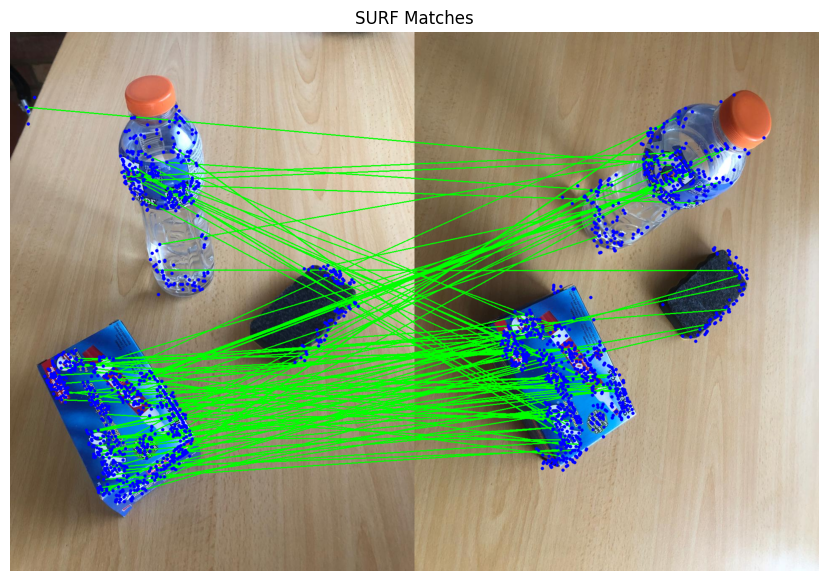

In [20]:
import cv2
import numpy as np
import mahotas
from mahotas.features import surf
import matplotlib.pyplot as plt

# -------------------------------
# Cargar imágenes
# -------------------------------

img1 = cv2.imread(img1_path)
img2 = cv2.imread(img2_path)
if img1 is None or img2 is None:
    raise FileNotFoundError("Alguna imagen no se encontró.")

gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

# -------------------------------
# Detectar puntos SURF y descriptores con Mahotas
# -------------------------------
kp1 = surf.surf(gray1)
kp2 = surf.surf(gray2)

pts1 = kp1[:, :2]        # posiciones (y,x)
desc1 = kp1[:, 2:]       # resto como descriptor
pts2 = kp2[:, :2]
desc2 = kp2[:, 2:]

# -------------------------------
# Emparejamiento de descriptores (distancia euclidiana + ratio test)
# -------------------------------
ratio = 0.5  # Más pequeño entonces más selectivo
matches = []
for i, d1 in enumerate(desc1):
    distances = np.linalg.norm(desc2 - d1, axis=1)
    if len(distances) < 2:
        continue
    j = np.argmin(distances)
    sorted_distances = np.sort(distances)
    if sorted_distances[0] < ratio * sorted_distances[1]:  # ratio test simple
        matches.append((i, j))

# -------------------------------
# Visualizar matches con líneas mejoradas
# -------------------------------
h1, w1 = img1.shape[:2]
h2, w2 = img2.shape[:2]

fig, ax = plt.subplots(figsize=(14, 7))
# Imagen concatenada
out_img = np.zeros((max(h1,h2), w1+w2, 3), dtype=np.uint8)
out_img[:h1, :w1] = img1
out_img[:h2, w1:w1+w2] = img2

# Dibujar líneas entre puntos emparejados
for i, j in matches:
    y1, x1 = pts1[i]
    y2, x2 = pts2[j]
    pt1 = (int(x1), int(y1))
    pt2 = (int(x2) + w1, int(y2))
    cv2.line(out_img, pt1, pt2, (0, 255, 0), 2)  # Verde brillante, grosor 2

# Dibujar círculos en los puntos clave
for (y, x) in pts1:
    cv2.circle(out_img, (int(x), int(y)), 4, (255,0,0), -1)  # azul
for (y, x) in pts2:
    cv2.circle(out_img, (int(x)+w1, int(y)), 4, (255,0,0), -1)  # azul

# Mostrar
ax.imshow(cv2.cvtColor(out_img, cv2.COLOR_BGR2RGB))
ax.set_title("SURF Matches")
ax.axis('off')
plt.show()


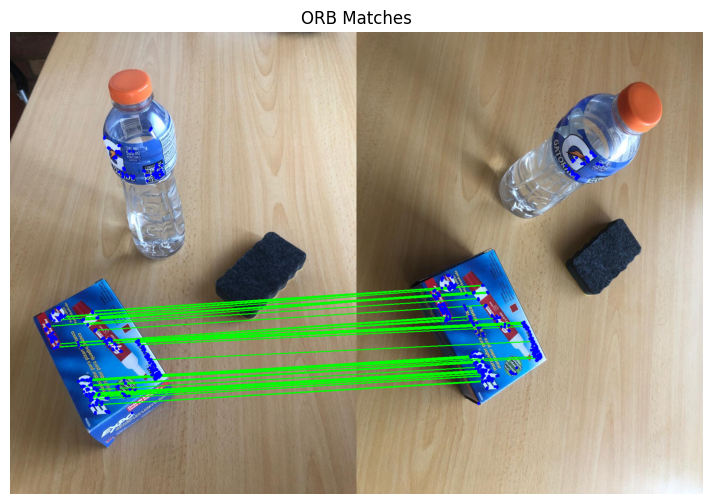

In [17]:
# -------------------------------
# ORB
# -------------------------------
orb = cv2.ORB_create()
kp1_orb, des1_orb = orb.detectAndCompute(gray1, None)
kp2_orb, des2_orb = orb.detectAndCompute(gray2, None)

# Emparejamiento con BFMatcher
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches_orb = bf.match(des1_orb, des2_orb)
matches_orb = sorted(matches_orb, key=lambda x: x.distance)
good_matches_orb = [(m.queryIdx, m.trainIdx) for m in matches_orb[:50]]  # matches_orb[:50], selecciona los 50 matches más cercanos (los “mejores”).

draw_matches(img1, [kp.pt for kp in kp1_orb], img2, [kp.pt for kp in kp2_orb], good_matches_orb, "ORB Matches")


<hr style="border: 4px solid red;">